# EquityAgent: Financial Research Evaluation and Optimization Framework
### Evaluation Lead Technical Appendix | AAI 520 Final Team Project

**Report date:** October 16, 2026  
**Scope:** Independent evaluation extension and reproducible offline validation  
**Relationship to team deliverable:** Supporting technical notebook; **not** a substitute for the team's full agent notebook or a demonstration of live LangGraph integration.

#### Objective

Assess the reliability of an investment research report *after* synthesis by combining structured LLM quality assessments with deterministic checks of recognized financial claims. Demonstrate how evaluator feedback can guide revision, how a valid higher-scoring draft is selected, and how reflection lessons are screened and retrieved across runs.

#### Results summary

| Evaluation case | Evidence in this notebook | Observed outcome |
|:--|:--|:--|
| Financial figure and arithmetic validation | Synthetic revenue claim and growth calculation | **2 contradictions** detected |
| Combined quality policy and revision | Mock rubric scores plus deterministic audit | Flawed report rejected; corrected revision accepted |
| Best candidate selection | Predetermined draft averages of 4.6 and 4.4 | Earlier **4.6** draft retained |
| Reflection and memory | Temporary JSON storage and sample dated lessons | Invalid tool lesson rejected; newer relevant note first |
| Evidence-matched baseline interface | Mock baseline and mock judge, shared findings | **0.6 illustrative difference**, not measured performance |
| Real-company or live-model evaluation | Not performed here | **Not established** |

**Evidence classification:** All demonstrations below use controlled synthetic fixtures and scripted or mock evaluator responses. Existing team stock results are separately labeled contextual evidence. The notebook preserves saved execution outputs so the reader can inspect the results without paid model calls.

**AI assistance and authorship:** ChatGPT was used substantially to draft source modules, test scaffolding, and this notebook. The student ran and tested the code locally and must review, understand, and clearly disclose AI-generated assistance before submission. A detailed disclosure appears at the end.


## 1. Environment and module imports

The implementation imports the existing project's Pydantic schemas (`Draft`, `Finding`, `Evaluation`, and `Reflection`) and adds separate evaluation, numeric validation, memory, and benchmarking modules. The notebook runs from either the repository root or its `notebooks/` directory.

**Reproducibility:** Python 3.12.13 was used for the saved execution. A local virtual environment with `pydantic`, `pandas`, `matplotlib`, `pytest`, and Jupyter kernel support is required. This notebook does not require financial API credentials. The student reported `127 passed in 1.91s` for the repository test suite on October 16; the test suite was run in the terminal, not in this notebook.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open this notebook from the GitHub repository or notebooks folder")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import tempfile
import pandas as pd
import matplotlib.pyplot as plt

from src.agents.schemas import Draft, Evaluation, Finding, Reflection
from src.agents.evaluation_lead import QualityPolicy, run_evaluation_cycle
from src.agents.numeric_validation import audit_numeric_claims
from src.agents.evaluation_pipeline import run_reviewed_cycle
from src.memory.evaluation_memory import EvaluationMemory, select_lessons
from src.evaluation_lead_benchmarks import compare_evidence_matched

print("Repository:", ROOT)
print("All examples in this notebook are synthetic unless labeled otherwise.")

Repository: /Users/pawan/Desktop/USD AAI/AAI-520 NLP/Final Project/MS_AAI_520_NLP_GenAI_Final
All examples in this notebook are synthetic unless labeled otherwise.


### Architecture and acceptance methodology

The complete team system uses the flow **ticker → plan → route → specialist findings → synthesize draft → evaluate and optimize → reflect and remember**. This extension begins at the **draft and findings** boundary. It does not replace the planner, data tools, or news chain.

| Extension module | Responsibility | Inputs and outputs |
|:--|:--|:--|
| `src/agents/evaluation_lead.py` | Rule-based acceptance policy, revision history, best valid draft selection | `Draft`, `Evaluation` → candidate decision |
| `src/agents/numeric_validation.py` | Recognized financial claim and derived-growth checks | `Draft`, `Finding` list → claim audit |
| `src/agents/evaluation_pipeline.py` | Combines evaluator callbacks, numeric audit, revision feedback, and selection | draft plus findings → reviewed outcome |
| `src/memory/evaluation_memory.py` | Validates and persists reflection lessons and retrieves relevant records | `Reflection` → stored and selected notes |
| `src/evaluation_lead_benchmarks.py` | Scores a single-prompt baseline and agent report against frozen evidence | same findings → paired score rows |

**Acceptance policy in the default Phase 1 implementation:** Average evaluator score at least **4.0/5**, accuracy at least **4/5**, evidence at least **4/5**, at least one revision, and at most three evaluated candidates. The integrated pipeline additionally requires no detected numeric contradictions among **recognized** claims. When the evaluation budget is exhausted without passing, the result is explicitly marked unsuccessful.

**Validity boundary:** LLM scores are estimates, not proof of financial accuracy. A deterministic audit can only verify the patterns it recognizes against the evidence supplied to it. Findings themselves are not independently confirmed against raw SEC filings or API payloads here.

## 2. Synthetic reference evidence and intentionally incorrect report

The fixture is a hypothetical company marked `DEMO`, **not** NVDA, JPM, or XOM. Its specialist finding states FY2025 revenue of **$100 billion**. The draft makes two independently testable claims:

1. FY2025 revenue was **$150 billion**, contradicting the supplied finding.
2. Revenue increased from **$100 billion** to **$120 billion**, a purported **35%** increase. The correct arithmetic is **20%**.

The experiment tests detection of a direct source mismatch and an incorrect derived percentage, not accuracy of any real company's accounts.


In [2]:
findings = [Finding(
    route="earnings",
    summary="Synthetic reference data for a hypothetical company.",
    key_figures=["Revenue FY2025: $100B"],
    risks=["Concentration risk"],
    sources=["synthetic_evidence_fixture"],
)]

flawed_draft = Draft(
    ticker="DEMO",
    thesis="Synthetic equity research example for testing only.",
    bull_case=["Demand could improve."],
    bear_case=["Costs could rise."],
    fundamentals=(
        "Revenue FY2025: $150B. "
        "Revenue increased from $100B to $120B, a calculated increase of 35%."
    ),
    news_and_catalysts="No source backed news in this synthetic fixture.",
    market_and_macro="No macro data supplied for this fixture.",
    conclusion="Illustrative analysis, not investment advice.",
)
print("Fixture findings:", findings[0].key_figures)
print("Flawed draft:", flawed_draft.fundamentals)

Fixture findings: ['Revenue FY2025: $100B']
Flawed draft: Revenue FY2025: $150B. Revenue increased from $100B to $120B, a calculated increase of 35%.


## 3. Deterministic financial claim audit

`audit_numeric_claims()` compares **recognized** metric, amount, unit, and reporting-period statements against specialist `Finding` data and checks specified growth calculations using arithmetic. Results are classified as `supported`, `contradicted`, or `unverified`.

The audit is deliberately narrower than unrestricted fact checking. In particular, a `supported` result means consistency with *supplied findings* or an explicit calculation, **not independent verification against original market or filing data**. Unrecognized prose is not necessarily flagged as unverified and should be reviewed separately.


In [3]:
initial_audit = audit_numeric_claims(flawed_draft, findings)
audit_table = pd.DataFrame(initial_audit.rows())
display(audit_table)
assert len(initial_audit.contradictions) >= 2, "The fixture should reveal two contradictions"
print("Recognized claims:", len(initial_audit.checks))
print("Contradictions:", len(initial_audit.contradictions))
print("Unverified:", len(initial_audit.unverified))

,kind,status,metric,period,observed,expected,reason,excerpt
0,reported,contradicted,revenue,FY2025,150000000000,100000000000,value_differs_from_findings,Revenue FY2025: $150B
1,derived_growth,contradicted,revenue,NaN,35,20.0,incorrect_percentage_change,"Revenue increased from $100B to $120B, a calcu..."


Recognized claims: 2
Contradictions: 2
Unverified: 0


## 4. Joint acceptance policy and revision feedback

The example deliberately assigns a report **perfect mocked qualitative scores** to isolate the numeric gate. The numeric audit must nevertheless reject the inaccurate initial report. A scripted optimizer receives the detected issue as feedback and replaces the two erroneous figures with controlled correct values.

**Experimental control:** The synthetic evaluator always scores 5.0. Therefore, acceptance differences in this test are attributable to the deterministic audit. The exercise demonstrates an interface and invariant, not the ability of a real LLM to revise financial reports reliably.


In [4]:
feedback_received = []

def synthetic_evaluator(draft: Draft, evidence: list[Finding]) -> Evaluation:
    return Evaluation(
        completeness=5, evidence=5, accuracy=5, balance=5, clarity=5,
        critiques=["Verify any financial figures against supplied evidence."],
    )

def synthetic_optimizer(
    draft: Draft, evaluation: Evaluation, evidence: list[Finding]
) -> Draft:
    feedback_received.extend(evaluation.critiques)
    return draft.model_copy(update={
        "fundamentals": (
            "Revenue FY2025: $100B. "
            "Revenue increased from $100B to $120B, a calculated increase of 20%."
        )
    })

reviewed = run_reviewed_cycle(
    flawed_draft, findings,
    evaluate_fn=synthetic_evaluator,
    optimize_fn=synthetic_optimizer,
)
revision_table = pd.DataFrame(reviewed.rows())
display(revision_table)
assert reviewed.accepted
assert reviewed.selected_iteration == 1
assert len(reviewed.history[0].audit.contradictions) >= 2
assert not reviewed.history[1].audit.contradictions
assert any("Numeric contradiction" in f for f in feedback_received)
print("Chosen draft fundamentals:", reviewed.draft.fundamentals)
print("Decision:", reviewed.stop_reason)
print("Note: mocked LLM scores stayed at 5; acceptance changed due to numeric checks.")

,iteration,average,accuracy,evidence,numeric_checked,numeric_contradicted,numeric_unverified,accepted,failures,selected
0,0,5.0,5,5,2,2,0,False,[numeric_contradictions],False
1,1,5.0,5,5,2,0,0,True,[],True


Chosen draft fundamentals: Revenue FY2025: $100B. Revenue increased from $100B to $120B, a calculated increase of 20%.
Decision: accepted_by_both_checks
Note: mocked LLM scores stayed at 5; acceptance changed due to numeric checks.


## 5. Selection of the highest-scoring acceptable candidate

A separate controlled experiment assigns an original draft an average of **4.6** and its revision **4.4**. Both meet the acceptance thresholds. The selection mechanism must return the **earlier, higher-rated** candidate, rather than automatically choosing the last evaluated draft.

The scores are scripted fixtures, not observed judge preferences. This isolates the correctness of the candidate-selection algorithm.


In [5]:
def regression_evaluator(draft: Draft, evidence: list[Finding]) -> Evaluation:
    if "INITIAL" in draft.thesis:
        scores = (5, 5, 5, 4, 4)   # average 4.6
    else:
        scores = (5, 4, 4, 4, 5)   # average 4.4
    return Evaluation(
        completeness=scores[0], evidence=scores[1], accuracy=scores[2],
        balance=scores[3], clarity=scores[4], critiques=[],
    )

def regression_optimizer(draft: Draft, evaluation: Evaluation, evidence: list[Finding]) -> Draft:
    return draft.model_copy(update={"thesis": "REVISED synthetic draft"})

regression_start = reviewed.draft.model_copy(update={"thesis": "INITIAL synthetic draft"})
selection = run_evaluation_cycle(
    regression_start, findings,
    evaluate_fn=regression_evaluator,
    optimize_fn=regression_optimizer,
    policy=QualityPolicy(min_revisions=1, max_evaluations=3),
)
display(pd.DataFrame(selection.rows()))
assert selection.accepted
assert selection.selected_iteration == 0
print("Best accepted iteration:", selection.selected_iteration)
print("Best accepted average:", selection.evaluation.average)

,iteration,average,accuracy,evidence,passed,failures,selected
0,0,4.6,5,5,True,[],True
1,1,4.4,4,4,True,[],False


Best accepted iteration: 0
Best accepted average: 4.6


## 6. Reflection and persistent memory behavior

A structured `Reflection` supplies reusable lessons. The memory extension screens duplicates and explicit references to tools that are not recognized, supports a dry-run preview, and prioritizes relevant, recent records. This addresses a previously identified possibility of retrieving stale lessons first.

The notebook uses a **temporary JSON file** and does not alter the team's `memory/notes.json`. Structural checks cannot determine whether a lesson is strategically useful or true, and retrieval order alone does not demonstrate improvement in subsequent agent performance.


In [6]:
reflection = Reflection(
    weakest_section="Synthetic fundamentals",
    unsupported_claims=["Incorrect revenue figure"],
    missing_data=["No original filing provided"],
    failed_tools=[],
    what_to_change=["Check fiscal year and currency units before writing"],
    confidence="medium",
    lessons=[
        "Verify fiscal year and amount before drafting the revenue section.",
        "Use get_company_peers for valuation crosschecks.",  # deliberately unavailable
    ],
)
with tempfile.TemporaryDirectory() as temp_dir:
    memory_path = Path(temp_dir) / "evaluation_notes.json"
    memory = EvaluationMemory(memory_path)
    preview = memory.add_reflection(
        "DEMO", "Technology", reflection,
        today=date(2026, 10, 16), persist=False,
    )
    assert not memory_path.exists()  # preview must not write
    assert len(preview.added_notes) == 1
    assert any(item.reason == "unknown_explicit_tool" for item in preview.rejected)
    print("Preview lessons accepted:", len(preview.added_notes))
    print("Preview lessons rejected:", [(r.lesson, r.reason) for r in preview.rejected])
    persisted = memory.add_reflection(
        "DEMO", "Technology", reflection,
        today=date(2026, 10, 16), persist=True,
    )
    assert persisted.saved and memory_path.exists()
    print("Temporary records stored:", len(memory.load()))

sample_notes = [
    {"ticker":"DEMO", "sector":"Technology", "date":"2026-10-01", "lesson":"Older relevant note"},
    {"ticker":"DEMO", "sector":"Technology", "date":"2026-10-15", "lesson":"Newer relevant note"},
    {"ticker":"OTHER", "sector":"Industrials", "date":"2026-10-16", "lesson":"Irrelevant note"},
]
selected = select_lessons(sample_notes, "DEMO", "Technology", limit=2)
assert [n["lesson"] for n in selected] == ["Newer relevant note", "Older relevant note"]
display(pd.DataFrame(selected))

Preview lessons accepted: 1
Preview lessons rejected: [('Use get_company_peers for valuation crosschecks.', 'unknown_explicit_tool')]
Temporary records stored: 1


,ticker,sector,date,lesson
0,DEMO,Technology,2026-10-15,Newer relevant note
1,DEMO,Technology,2026-10-01,Older relevant note


## 7. Evidence-matched benchmark interface

A valid comparison of downstream report creation should hold research inputs constant. The benchmark function accepts the same frozen `Finding` objects for the one-pass baseline and reviewed report and records both evaluations using a common judge interface.

**This notebook does not execute that live experiment.** It supplies a scripted baseline report and a mock judge that awards the baseline 4.0 and the reviewed report 4.6. These predetermined values create a **0.6 illustrative score difference** and demonstrate table/chart formatting only. They **must not be presented as empirical evidence** of model superiority or improved investment research accuracy.

Even with a real evidence-matched experiment, this design would evaluate downstream writing and revision with common inputs; it would not isolate the independent benefit of planning or data retrieval.


In [7]:
def baseline_fixture(ticker: str, evidence: list[Finding]) -> Draft:
    return reviewed.draft.model_copy(update={
        "ticker": ticker,
        "thesis": "SYNTHETIC BASELINE: One pass using the same evidence.",
    })

def synthetic_judge(draft: Draft, evidence: list[Finding]) -> Evaluation:
    vals = (4, 4, 4, 4, 4) if draft.thesis.startswith("SYNTHETIC BASELINE") else (5, 5, 5, 4, 4)
    return Evaluation(
        completeness=vals[0], evidence=vals[1], accuracy=vals[2],
        balance=vals[3], clarity=vals[4], critiques=[],
    )

comparison = compare_evidence_matched(
    "DEMO", findings, reviewed.draft,
    make_baseline=baseline_fixture,
    judge=synthetic_judge,
)
paired = pd.DataFrame(comparison.rows())
display(paired[["ticker", "candidate", "average", "accuracy", "evidence"]])
print("Synthetic paired score difference:", comparison.average_delta)
print("Shared evidence fingerprint:", comparison.evidence_sha256[:16], "...")
assert paired["evidence_sha256"].nunique() == 1

,ticker,candidate,average,accuracy,evidence
0,DEMO,matched_baseline,4.0,4,4
1,DEMO,reviewed_agent,4.6,5,5


Synthetic paired score difference: 0.6
Shared evidence fingerprint: cc9eca3db6e950b2 ...


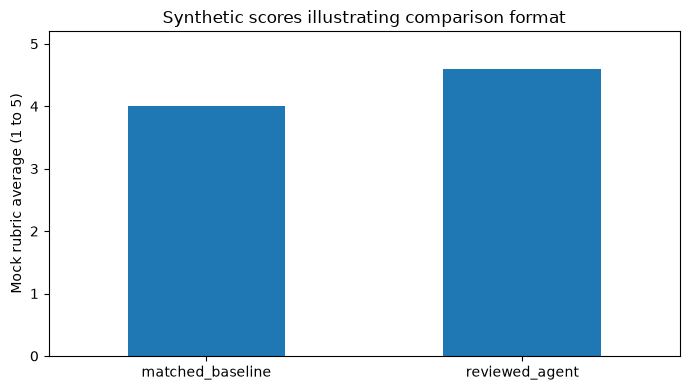

In [8]:
ax = paired.plot.bar(x="candidate", y="average", legend=False, rot=0, figsize=(7, 4))
ax.set_title("Synthetic scores illustrating comparison format")
ax.set_xlabel("")
ax.set_ylabel("Mock rubric average (1 to 5)")
ax.set_ylim(0, 5.2)
plt.tight_layout()
plt.show()

## 8. Previously reported team experiment results (context only)

The original team's previously executed notebook reported the following evaluator averages. **These values were not regenerated in this appendix** and arise from a different experiment: its baseline received only the ticker, while the full agent used retrieved financial evidence.

| Ticker | Original single-prompt baseline | Original full agent |
|:--|--:|--:|
| NVDA | 2.2 | 4.4 |
| JPM | 1.8 | 4.4 |
| XOM | 2.0 | 4.6 |

The experiment supports a descriptive difference between those two configurations, but **does not isolate the contribution of agent orchestration from the effect of giving one system more evidence**. It does not validate the new evaluation extension on live reports.

**Source within the team repository:** Executed EquityAgent final notebook, and team Slack results discussion dated October 14, 2026.


## 9. Optional live evaluation interface (disabled)

The code cell below is intentionally disabled. To run a real comparison, the team must first supply valid API credentials, a saved agent state containing actual specialist findings, and an explicit experimental protocol. Live model calls may incur costs and `run_agent()` can modify persistent memory unless configured otherwise.

**No live evaluation results are generated by the saved notebook.** Integrating the new review pipeline into `src/graph.py` also remains a separate engineering task.


In [9]:
RUN_LIVE_COMPARISON = False

if RUN_LIVE_COMPARISON:
    if "state" not in globals():
        raise RuntimeError("Provide a real graph state with findings and draft first")
    from src.agents.evaluator import evaluate
    from src.evaluation_lead_benchmarks import compare_evidence_matched
    result_live = compare_evidence_matched(
        state["ticker"], state["findings"], state["draft"], judge=evaluate
    )
    display(pd.DataFrame(result_live.rows()))
else:
    print("Live experiment skipped. No model calls were made.")

Live experiment skipped. No model calls were made.


## 10. Findings, limitations, and integration recommendation

### Verified offline demonstrations

| Research question | Outcome | Evidence type |
|:--|:--|:--|
| Can an inaccurate report be rejected despite perfect rubric scores? | Yes; 2 recognized numeric contradictions caused rejection | Synthetic fixture and assertions |
| Can numeric critiques guide a corrected revision? | Yes; the scripted revision had 0 recognized contradictions and passed | Synthetic optimizer callback |
| Can a weaker revision be avoided? | Yes; the earlier 4.6 candidate was selected over 4.4 | Predetermined scores |
| Can reflection lessons be filtered and selected by recency? | Yes; unknown explicit tool rejected and newer ticker lesson selected | Temporary memory and sample records |
| Can a matched-evidence benchmark be represented consistently? | Yes; shared evidence fingerprint and paired table were produced | Mock baseline and mock judge |

**Automated verification reported by the student:** On October 16, 2026, the local terminal run of `python -m pytest -q` completed with **127 passed in 1.91 seconds**. The notebook itself does not execute those tests. This count includes the pre-existing team tests and the new extension's tests.

### Limitations

1. The parser handles a constrained class of financial claim patterns, not arbitrary language, tables, or all numeric facts. A lack of detected contradictions does **not** establish that a report is free of numerical errors.
2. The `Finding` objects are treated as reference evidence; their accuracy against original SEC filings or market data has **not** been independently verified here.
3. The qualitative evaluator and optimizer in the demonstrated examples are **synthetic callbacks**, not calls to deployed LLMs.
4. The 0.6 benchmark difference is **predetermined and illustrative**. No live evidence-matched comparison was conducted.
5. Memory tests demonstrate persistence and retrieval behavior, not a measured gain in downstream report quality.
6. The new pipeline is **not connected to the live `src/graph.py` workflow** in this appendix. Real workflow integration and regression testing remain necessary before merging.

### Proposed team integration

The extension can be reviewed on a separate feature branch. A production integration would connect the numeric audit and review policy to the graph's evaluation decision, preserve the selected valid draft, add trace logs for rejection reasons, and only commit memory lessons after validation. The team should re-run the complete original notebook and compare changes on the **same real specialist findings**, recording costs, uncertainties, and failures.

### Academic integrity and AI assistance disclosure

OpenAI ChatGPT (GPT-6), accessed October 16, 2026, substantially assisted in **designing and drafting the new Python modules, test cases, synthetic demonstrations, notebook text, and this editorial revision**. The student executed the automated tests and notebook locally and is responsible for reviewing, understanding, editing where necessary, and verifying all results. These contributions must be disclosed to the course instructor and team; no AI-generated material should be represented as solely human-authored.

**Submission role:** This appendix provides targeted evidence for the Evaluation Lead component. The **team's final notebook and any supplemental report** must still demonstrate all required agent functions, workflow patterns, and the GitHub repository link.
